# Ajuste del dataset a 90 % no morosos / 10 % morosos
Entrada: `dataset_simulado.csv`  
Salida: `dataset_simulado_90_10.csv`

**Dos métodos (variable `METODO`)**
- `"reasignar"` *(por defecto)*: conserva las 8 399 filas y sus variables. Se ajusta una regresión logística de `mora` sobre las demás variables, se desplaza su intercepto hasta que la probabilidad media sea 10 % y se vuelve a sortear `mora`. Así se **mantienen las relaciones** entre `mora` y las variables (por ejemplo, menor ingreso → más mora), pero con otro nivel base. Como `tasa_interes` se había generado a partir de `mora`, **se vuelve a generar**.
- `"submuestreo"`: conserva todos los no morosos y descarta morosos hasta llegar al 10 %. No inventa datos, pero el dataset queda con unas 2 760 filas.

## 0. Configuración

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.special import expit, logit
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

RUTA_ENTRADA = "dataset_simulado.csv"
RUTA_SALIDA = "dataset_simulado_90_10.csv"
PROP_MORA = 0.10              # proporción objetivo de morosos
METODO = "reasignar"          # "reasignar" o "submuestreo"
PESO_MORA_EN_TASA = 8         # puntos de tasa que suma la mora (solo método "reasignar"); pon 0 para eliminar la fuga
# IMPORTANTE: no usar la misma semilla (42) con la que se generaron genero, estado_civil, etc.
# Con la misma semilla, los números aleatorios se repiten y mora queda ligada al genero.
SEMILLA = 2025

rng = np.random.default_rng(SEMILLA)

## 1. Situación actual

In [17]:
df = pd.read_csv(RUTA_ENTRADA)
df_original = df.copy()
print("Filas:", len(df))
print(df["mora"].value_counts().rename("n").to_frame().assign(pct=lambda t: t["n"] / len(df) * 100))

Filas: 8399
         n    pct
mora             
1     5915 70.425
0     2484 29.575


## 2. Ajuste de la proporción

In [18]:
if METODO == "reasignar":
    # --- 2.1 Modelo de mora actual (sin atraso ni tasa_interes) ---
    excluir = ["mora", "atraso", "tasa_interes"]
    X = df.drop(columns=excluir)
    num = X.select_dtypes(include="number").columns.tolist()
    cat = X.select_dtypes(exclude="number").columns.tolist()

    modelo = Pipeline([
        ("pre", ColumnTransformer([
            ("num", StandardScaler(), num),
            ("cat", OneHotEncoder(handle_unknown="ignore"), cat),
        ])),
        ("clf", LogisticRegression(max_iter=2000)),
    ])
    modelo.fit(X, df["mora"])
    p_actual = modelo.predict_proba(X)[:, 1]
    print("AUC del modelo de mora actual (en la misma muestra):", round(roc_auc_score(df["mora"], p_actual), 4))

    # --- 2.2 Desplazar el intercepto hasta que la probabilidad media sea PROP_MORA ---
    z = logit(np.clip(p_actual, 1e-6, 1 - 1e-6))
    lo, hi = -15.0, 15.0
    for _ in range(100):
        mid = (lo + hi) / 2
        if expit(z + mid).mean() > PROP_MORA:
            hi = mid
        else:
            lo = mid
    delta = (lo + hi) / 2
    p_nuevo = expit(z + delta)
    print(f"Desplazamiento del intercepto (logit): {delta:.3f} | probabilidad media nueva: {p_nuevo.mean():.4f}")

    # --- 2.3 Sortear mora y ajustar para llegar exactamente a PROP_MORA ---
    mora_nueva = rng.binomial(1, p_nuevo)
    objetivo = int(round(PROP_MORA * len(df)))
    dif = objetivo - int(mora_nueva.sum())
    if dif > 0:      # faltan morosos: convertir no morosos con mayor probabilidad
        cand = np.where(mora_nueva == 0)[0]
        w = p_nuevo[cand] / p_nuevo[cand].sum()
        mora_nueva[rng.choice(cand, size=dif, replace=False, p=w)] = 1
    elif dif < 0:    # sobran morosos: convertir morosos con menor probabilidad
        cand = np.where(mora_nueva == 1)[0]
        w = (1 - p_nuevo[cand]) / (1 - p_nuevo[cand]).sum()
        mora_nueva[rng.choice(cand, size=-dif, replace=False, p=w)] = 0

    df_nuevo = df.copy()
    df_nuevo["mora"] = mora_nueva

    # --- 2.4 Regenerar tasa_interes con la nueva mora (misma fórmula que antes) ---
    tasa = (
        35
        + PESO_MORA_EN_TASA * (df_nuevo["mora"] == 1)
        - 4 * df_nuevo["exp_otras_entidades"]
        - 4 * (np.log(df_nuevo["ingreso"].clip(lower=500)) - np.log(2500))
        + rng.normal(0, 5, size=len(df_nuevo))
    )
    df_nuevo["tasa_interes"] = tasa.clip(18, 90).round(2)

elif METODO == "submuestreo":
    n0 = int((df["mora"] == 0).sum())
    n1 = int(round(n0 * PROP_MORA / (1 - PROP_MORA)))
    df_nuevo = (pd.concat([df[df["mora"] == 0],
                           df[df["mora"] == 1].sample(n=n1, random_state=SEMILLA)])
                  .sample(frac=1, random_state=SEMILLA)
                  .reset_index(drop=True))
else:
    raise ValueError("METODO debe ser 'reasignar' o 'submuestreo'")

print("\nFilas finales:", len(df_nuevo))
print(df_nuevo["mora"].value_counts().rename("n").to_frame().assign(pct=lambda t: t["n"] / len(df_nuevo) * 100))

AUC del modelo de mora actual (en la misma muestra): 0.6382
Desplazamiento del intercepto (logit): -3.201 | probabilidad media nueva: 0.1000

Filas finales: 8399
         n    pct
mora             
0     7559 89.999
1      840 10.001


## 3. Verificación: ¿se conservaron las relaciones?

In [19]:
# 3.1 Tasa de mora (%) por categoría, antes y después
filas = []
for c in ["vivienda", "nivel_educ", "estado_civil", "forma_pago", "genero", "sector_economico"]:
    antes = df_original.groupby(c)["mora"].mean() * 100
    despues = df_nuevo.groupby(c)["mora"].mean() * 100
    t = pd.DataFrame({"variable": c, "antes_%": antes, "despues_%": despues})
    t["cociente despues/antes"] = t["despues_%"] / t["antes_%"]
    filas.append(t)
pd.concat(filas)

,variable,antes_%,despues_%,cociente despues/antes
ALQUILADA,vivienda,79.394,20.000,0.252
FAMILIAR,vivienda,72.134,10.507,0.146
PROPIA,vivienda,65.603,8.064,0.123
SECUNDARIA,nivel_educ,80.524,14.607,0.181
SIN EDUCACION,nivel_educ,66.667,9.524,0.143
TECNICA,nivel_educ,79.075,13.990,0.177
UNIVERSITARIA,nivel_educ,63.973,7.018,0.110
CASADO,estado_civil,69.666,9.916,0.142
CONVIVIENTE,estado_civil,69.959,9.467,0.135
DIVORCIADO,estado_civil,68.260,10.707,0.157


In [20]:
# 3.2 Medias de variables numéricas según mora, antes y después
cols = ["ingreso", "edad", "exp_otras_entidades", "tasa_interes", "atraso"]
comp = pd.concat({
    "antes": df_original.groupby("mora")[cols].mean(),
    "despues": df_nuevo.groupby("mora")[cols].mean(),
})
comp

ingreso   edad  exp_otras_entidades  tasa_interes  atraso
        mora                                                            
antes   0    5,701.000 37.994                0.521        31.396   2.737
        1    3,783.226 35.729                0.426        41.346   5.188
despues 0    4,493.193 36.543                0.462        32.798   4.462
        1    3,065.506 35.107                0.386        42.315   4.469

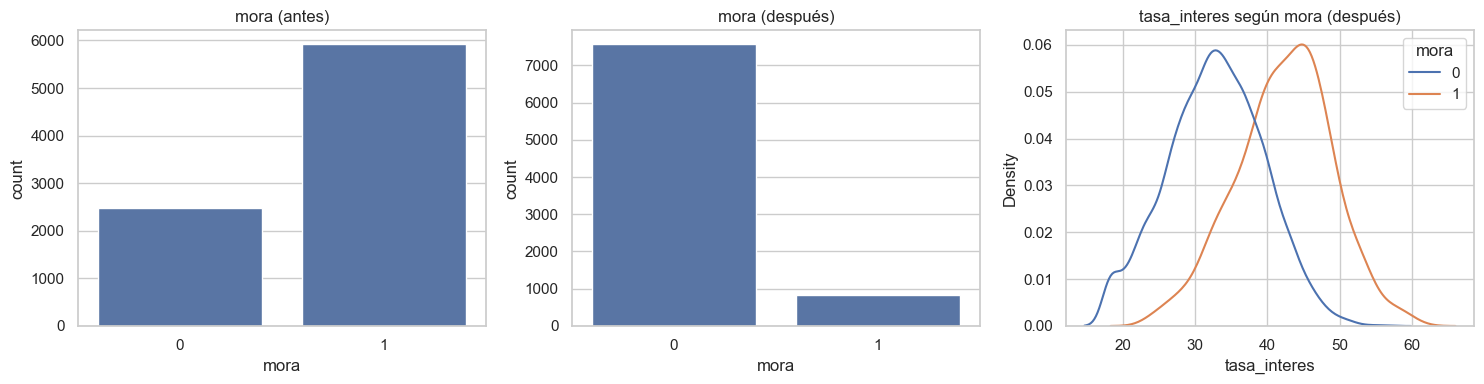

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (nombre, d) in zip(axes[:2], {"antes": df_original, "después": df_nuevo}.items()):
    sns.countplot(data=d, x="mora", ax=ax)
    ax.set_title(f"mora ({nombre})")
sns.kdeplot(data=df_nuevo, x="tasa_interes", hue="mora", common_norm=False, ax=axes[2])
axes[2].set_title("tasa_interes según mora (después)")
plt.tight_layout()
plt.show()

### 3.3 Alerta automática
`genero` casi no tenía relación con `mora` en el dataset original (≈ 71 % vs 70 %). Después del ajuste debe seguir igual.

In [22]:
t = df_nuevo.groupby("genero")["mora"].agg(n="count", pct_mora1=lambda s: s.mean() * 100)
print(t.round(2))
rango = t["pct_mora1"].max() - t["pct_mora1"].min()
print(f"\nDiferencia de tasa de mora entre géneros: {rango:.2f} puntos porcentuales")
assert rango < 3, "REVISAR: mora quedó relacionada con genero (¿se repitió la semilla?)"
print("OK: genero sigue sin relación fuerte con mora")

           n  pct_mora1
genero                 
F       3984      9.660
M       4415     10.310

Diferencia de tasa de mora entre géneros: 0.64 puntos porcentuales
OK: genero sigue sin relación fuerte con mora


## 4. Guardar

In [23]:
df_nuevo.to_csv(RUTA_SALIDA, index=False)
print("Guardado:", RUTA_SALIDA, df_nuevo.shape)
df_nuevo.head()

Guardado: dataset_simulado_90_10.csv (8399, 13)


,mora,atraso,vivienda,edad,ingreso,nivel_educ,genero,estado_civil,sector_economico,exp_otras_entidades,forma_pago,num_cuotas,tasa_interes
0,1,235,FAMILIAR,30,"3,500.000",UNIVERSITARIA,F,CONVIVIENTE,EDUCATIVO,1,MENSUAL,9,41.410
1,0,18,FAMILIAR,32,900.000,TECNICA,M,CASADO,EDUCATIVO,0,SEMANAL,24,43.970
2,0,0,FAMILIAR,26,"2,400.000",UNIVERSITARIA,F,SOLTERO,EDUCATIVO,0,MENSUAL,16,36.610
3,0,0,FAMILIAR,36,"2,700.000",TECNICA,F,CASADO,EDUCATIVO,0,QUINCENAL,13,29.470
4,1,0,FAMILIAR,46,"3,100.000",TECNICA,M,CONVIVIENTE,COMERCIO,0,MENSUAL,22,39.510


## Siguientes pasos
Los notebooks `01_eda`, `02_limpieza` y `03_modelado` actualizados ya leen `dataset_simulado_90_10.csv`. Vuelve a ejecutarlos en ese orden.